# Student Performance Prediction
## Comparing regression models with a reserved test set

Predict the final mathematics grade (G3, 0–20) from the UCI Student Performance dataset.
This replaces the previous synthetic productivity study after its source CSV could not be retrieved.
The old 4.51/4.55 results apply to the earlier dataset and are retired from the current project.

Cortez, P. (2008). *Student Performance*. UCI Machine Learning Repository.
https://doi.org/10.24432/C5TG7T · CC BY 4.0.

The mathematics file is used alone because students can appear in both subject files.
G1 and G2 are excluded to study prediction without prior-period grades. Absences is excluded
because the file does not establish that its cumulative value was available at the intended prediction time.
The remaining questionnaire fields also lack collection timestamps. Treat this as a retrospective
benchmark, with prospective use dependent on a feature-timing audit.


In [1]:
from pathlib import Path
import hashlib
import json
import platform
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, SGDRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, KFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PolynomialFeatures, StandardScaler

SEED = 42
DATA = Path("data/student-mat.csv")
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)
df = pd.read_csv(DATA, sep=";")
assert df.shape == (395, 33), df.shape
assert df["G3"].between(0, 20).all()
assert df.index.is_unique
print(f"Rows: {len(df)} | columns: {df.shape[1]}")
print("CSV SHA256:", hashlib.sha256(DATA.read_bytes()).hexdigest())


Rows: 395 | columns: 33
CSV SHA256: e47f9ee225e1ee6e69b7564e6dac7123e80b8486677fe111f351964cef5dec80


## Reserve the test set first

Use a fixed 80/20 split. All preprocessing and hyperparameter selection use the training
partition and shuffled four-fold cross-validation. A random split estimates performance for
similar students from these schools. External-school and future-cohort performance require
separate evaluation. Sensitive questionnaire variables are retained for this benchmark and
documented in the source dictionary; their collection, fairness, and usefulness need review
before any application involving students.


In [2]:
X = df.drop(columns=["G3", "G1", "G2", "absences"])
y = df["G3"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED
)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_train.index) | set(X_test.index) == set(df.index)
assert not {"G3", "G1", "G2", "absences"} & set(X.columns)
print(f"Training rows: {len(X_train)} | reserved test rows: {len(X_test)}")
print("Training target summary")
display(y_train.describe().to_frame("G3"))
print("Training missing cells:", int(X_train.isna().sum().sum()))


Training rows: 316 | reserved test rows: 79
Training target summary


,G3
count,316.000000
mean,10.325949
std,4.590337
min,0.000000
25%,8.000000
50%,11.000000
75%,13.000000
max,20.000000


Training missing cells: 0


## Fit preprocessing within each fold

Numeric values are imputed and scaled. Categorical values are imputed and one-hot encoded.
Degree-two expansion applies only to numeric columns. Compare a training-mean baseline,
linear regression, Ridge, and SGD with L1, L2, and Elastic Net regularization.
The smallest mean validation RMSE selects the final configuration. Baseline participates
in selection, so a model must earn its added complexity. Fold spread is descriptive.


In [3]:
numeric = X_train.select_dtypes(include="number").columns.tolist()
categorical = X_train.select_dtypes(exclude="number").columns.tolist()
preprocess = ColumnTransformer([
    ("numeric", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("poly", PolynomialFeatures(degree=1, include_bias=False)),
        ("scale", StandardScaler()),
    ]), numeric),
    ("categorical", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encode", OneHotEncoder(handle_unknown="ignore", drop="first", sparse_output=False)),
    ]), categorical),
])
pipeline = Pipeline([("preprocess", preprocess), ("model", DummyRegressor())])
parameter_grid = [
    {"model": [DummyRegressor(strategy="mean")]},
    {"model": [LinearRegression()]},
    {"model": [Ridge()], "model__alpha": [0.1, 1.0, 10.0, 100.0],
     "preprocess__numeric__poly__degree": [1, 2]},
    {"model": [SGDRegressor(max_iter=20000, tol=1e-5, random_state=SEED)],
     "model__penalty": ["l1", "l2", "elasticnet"],
     "model__alpha": [0.0001, 0.001, 0.01]},
]
cv = KFold(n_splits=4, shuffle=True, random_state=SEED)
search = GridSearchCV(pipeline, parameter_grid, scoring="neg_root_mean_squared_error",
                      cv=cv, refit=True, error_score="raise", n_jobs=1)
with warnings.catch_warnings():
    warnings.simplefilter("error", ConvergenceWarning)
    search.fit(X_train, y_train)
records = []
for index, params in enumerate(search.cv_results_["params"]):
    record = {
        "model": type(params["model"]).__name__,
        "parameters": str({key: value for key, value in params.items() if key != "model"}),
        "cv_rmse": -search.cv_results_["mean_test_score"][index],
        "fold_sd": search.cv_results_["std_test_score"][index],
    }
    for fold in range(4):
        record[f"fold_{fold+1}_rmse"] = -search.cv_results_[f"split{fold}_test_score"][index]
    records.append(record)
comparison = pd.DataFrame(records).sort_values("cv_rmse")
comparison.to_csv(RESULTS / "cross_validation.csv", index=False)
display(comparison)
print("Selected using training CV only:", search.best_params_)


,model,parameters,cv_rmse,fold_sd,fold_1_rmse,fold_2_rmse,fold_3_rmse,fold_4_rmse
8,Ridge,"{'model__alpha': 100.0, 'preprocess__numeric__...",4.257912,0.218515,3.952400,4.419598,4.154936,4.504713
9,Ridge,"{'model__alpha': 100.0, 'preprocess__numeric__...",4.272463,0.206486,3.964853,4.378626,4.224256,4.522118
6,Ridge,"{'model__alpha': 10.0, 'preprocess__numeric__p...",4.345699,0.195047,4.033538,4.461795,4.338780,4.548683
4,Ridge,"{'model__alpha': 1.0, 'preprocess__numeric__po...",4.460988,0.150761,4.208564,4.538871,4.493949,4.602568
16,SGDRegressor,"{'model__alpha': 0.01, 'model__penalty': 'l1'}",4.466904,0.203537,4.130768,4.638881,4.479441,4.618525
18,SGDRegressor,"{'model__alpha': 0.01, 'model__penalty': 'elas...",4.469510,0.201304,4.138594,4.646996,4.477975,4.614475
17,SGDRegressor,"{'model__alpha': 0.01, 'model__penalty': 'l2'}",4.469525,0.200782,4.138664,4.645059,4.480441,4.613934
2,Ridge,"{'model__alpha': 0.1, 'preprocess__numeric__po...",4.488204,0.138603,4.253499,4.556722,4.530967,4.611628
14,SGDRegressor,"{'model__alpha': 0.001, 'model__penalty': 'l2'}",4.490055,0.190410,4.176980,4.661040,4.499144,4.623058
15,SGDRegressor,"{'model__alpha': 0.001, 'model__penalty': 'ela...",4.490091,0.190502,4.176955,4.661373,4.498925,4.623110


Selected using training CV only: {'model': Ridge(), 'model__alpha': 100.0, 'preprocess__numeric__poly__degree': 1}


## Evaluate the locked choice

Evaluate the selected configuration and the training-mean baseline once on the reserved test
partition. Report RMSE and MAE in grade points and R². Predictions remain unclipped, matching
the selection criterion. A bootstrap interval summarizes uncertainty for this fixed model on
the test sample; it does not measure uncertainty from retraining or new schools.


In [4]:
selected = search.best_estimator_
prediction = selected.predict(X_test)
baseline = DummyRegressor(strategy="mean").fit(X_train, y_train)
baseline_prediction = baseline.predict(X_test)
evaluation = pd.DataFrame([
    {"model": "Training mean", "rmse": root_mean_squared_error(y_test, baseline_prediction),
     "mae": mean_absolute_error(y_test, baseline_prediction), "r2": r2_score(y_test, baseline_prediction)},
    {"model": type(selected["model"]).__name__, "rmse": root_mean_squared_error(y_test, prediction),
     "mae": mean_absolute_error(y_test, prediction), "r2": r2_score(y_test, prediction)},
])
rng = np.random.default_rng(SEED)
errors = y_test.to_numpy() - prediction
bootstrap_rmse = [np.sqrt(np.mean(rng.choice(errors, size=len(errors), replace=True)**2))
                  for _ in range(2000)]
interval = np.quantile(bootstrap_rmse, [0.025, 0.975])
evaluation.to_csv(RESULTS / "test_evaluation.csv", index=False)
pd.DataFrame({"row": X_test.index, "actual": y_test, "prediction": prediction,
              "baseline": baseline_prediction}).to_csv(RESULTS / "test_predictions.csv", index=False)
summary = {
    "dataset": "UCI Student Performance, mathematics",
    "csv_sha256": hashlib.sha256(DATA.read_bytes()).hexdigest(),
    "rows": len(df), "train_rows": len(X_train), "test_rows": len(X_test), "seed": SEED,
    "excluded": ["G1", "G2", "absences"], "target": "G3 (0–20 grade points)",
    "selected_model": type(selected["model"]).__name__,
    "selected_parameters": {key: str(value) for key, value in search.best_params_.items()},
    "cv_rmse": -search.best_score_, "test_metrics": evaluation.to_dict(orient="records"),
    "test_rmse_bootstrap_95_percent": interval.tolist(),
    "python": platform.python_version(), "sklearn": sklearn.__version__,
}
(RESULTS / "summary.json").write_text(json.dumps(summary, indent=2) + "\n")
display(evaluation)
print("Fixed-model test RMSE bootstrap interval:", interval)
print("Predictions outside 0–20:", int(((prediction < 0) | (prediction > 20)).sum()))


,model,rmse,mae,r2
0,Training mean,4.550181,3.645850,-0.009710
1,Ridge,4.153481,3.348885,0.158675


Fixed-model test RMSE bootstrap interval: [3.48128814 4.83760534]
Predictions outside 0–20: 0


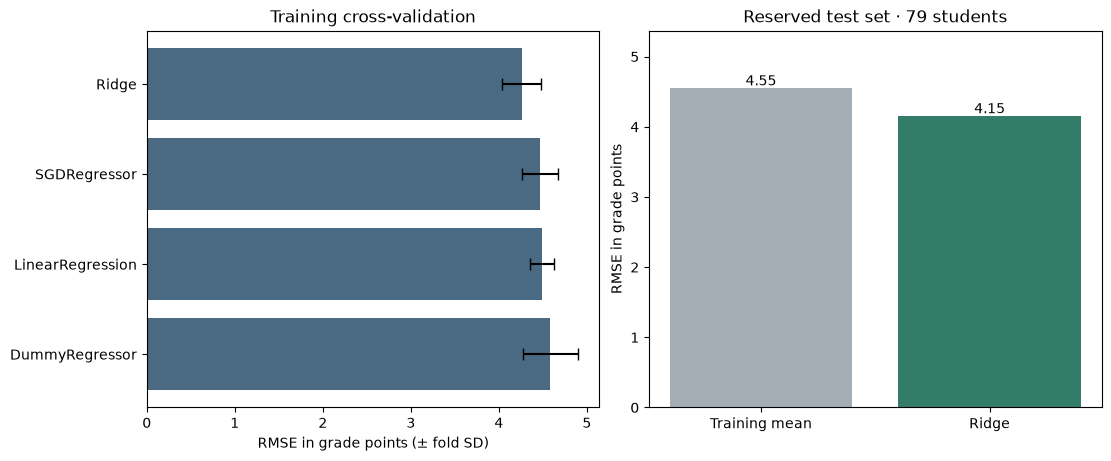

In [5]:
best_by_family = comparison.sort_values("cv_rmse").drop_duplicates("model")
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), layout="constrained")
axes[0].barh(best_by_family["model"], best_by_family["cv_rmse"],
             xerr=best_by_family["fold_sd"], color="#496a82", capsize=4)
axes[0].invert_yaxis()
axes[0].set(title="Training cross-validation", xlabel="RMSE in grade points (± fold SD)")
axes[1].bar(evaluation["model"], evaluation["rmse"], color=["#a4adb4", "#327c68"])
axes[1].set(title=f"Reserved test set · {len(X_test)} students", ylabel="RMSE in grade points")
for index, value in enumerate(evaluation["rmse"]):
    axes[1].text(index, value + 0.04, f"{value:.2f}", ha="center")
axes[1].set_ylim(0, evaluation["rmse"].max() * 1.18)
fig.savefig(RESULTS / "model-comparison.png", dpi=180)
plt.show()


## Interpretation and interview discussion

Read the baseline beside the selected model. Improvements quantify error reduction on this
particular split. Explain the retained error and small test sample alongside any improvement.

The dataset provides historical observational records from two schools. Associations cannot
establish the effect of changing a student's habits. The pipeline demonstrates model evaluation,
preprocessing isolation, and reproducibility. Prospective usefulness remains untested.

The original study explored synthetic productivity scores. This replacement uses a different
target, population, and feature set, so its scores have their own units and interpretation.
Development and evaluation revisions were implemented with Codex assistance under my direction.
